In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
def plot(eig_lifted, eig_distr_pca, samples, means, Sigmas, title=None, weights=None, bary_lifted_pca=None):

    if weights is None:
        weights = np.ones(len(eig_lifted))
    weights = np.asarray(weights, dtype=float)

    max_weight = weights.max()
    if max_weight > 0:
        # Scale by the absolute maximum to avoid exaggerating tiny differences.
        alpha = 0.2 + 0.8 * weights / max_weight
        alpha = np.clip(alpha, 0.0, 1.0)
    else:
        alpha = np.ones_like(weights)

    index_max_alpha = np.argmax(alpha)

    for k in range(len(samples)):
        plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
        draw_cov(means[k], Sigmas[k], nstd=1)
    
    plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")
    
    ts = torch.linspace(-5, 5, 100)

    if bary_lifted_pca is not None:
        pc = ts[:,None] * bary_lifted_pca[0][None]
        plt.plot(pc[:,0], pc[:,1], c="orange", lw=2, label="Barycenter Lifted PCA")

    pc = ts[:,None] * eig_distr_pca[0][None]
    plt.plot(pc[:,0], pc[:,1], c="black", label="UAPCA")
    
    for k in range(len(eig_lifted)):
        pc = ts[:,None] * eig_lifted[k,:,0][None]
        line_kwargs = {
            "c": "orange",
            "alpha": alpha[k],
            "lw": 0.8 + alpha[k],
            "zorder": 3,
        }

        if k == index_max_alpha:
            line_kwargs.update({"lw": 2.2, "label": "Lifted PCA"})

        plt.plot(pc[:,0], pc[:,1], **line_kwargs)

    if title is not None:
        plt.title(title)

    plt.legend()
    
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    plt.show()

## Example of Niculae

In [3]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, m4 = [-0.5, -2], [0.5, -1], [-0.5, 0], [0.5, 1]
means = torch.tensor([m1, m2, m3, m4])

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * 1000 for k in range(4)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

concat_samples = concat_samples - torch.mean(concat_samples, axis=0, keepdims=True)

INFO:2026-09-09 18:54:48,090:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


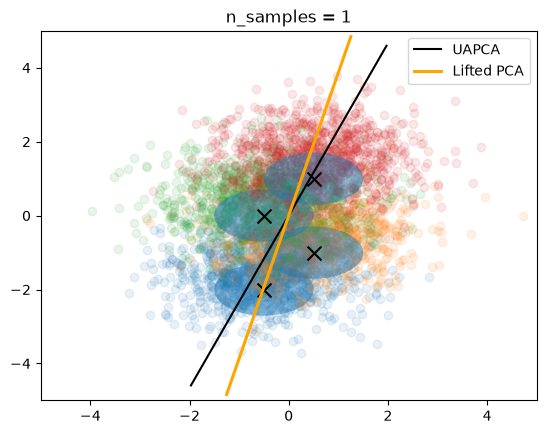

n=1 Lifted 1.1208921855015 Distributional 1.1012437431630735


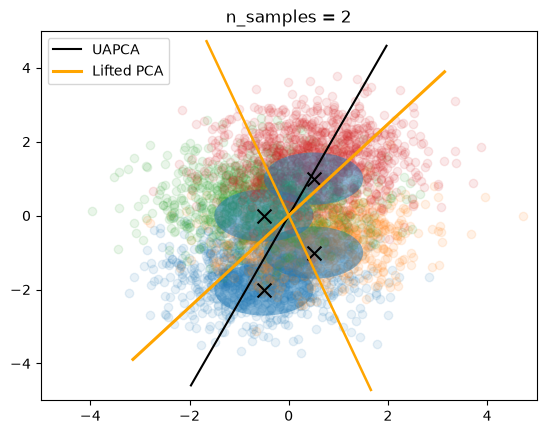

n=2 Lifted 0.5486081716814406 Distributional 1.1012437431630735


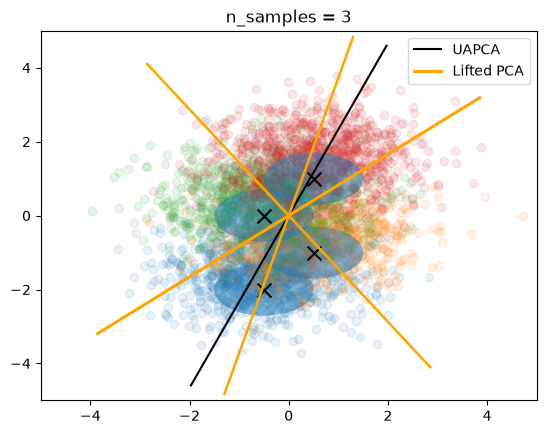

n=3 Lifted 0.3251267409611931 Distributional 1.1012437431630735


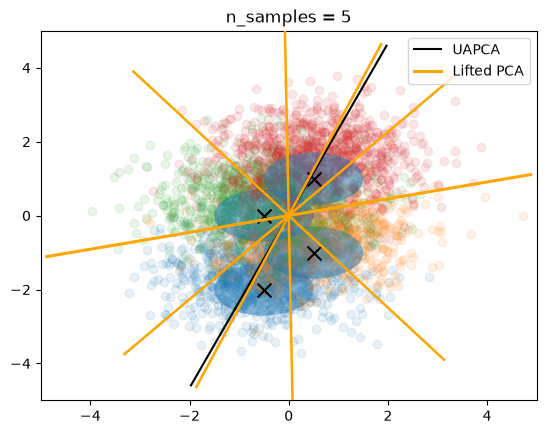

n=5 Lifted 0.16700222380597837 Distributional 1.1012437431630735


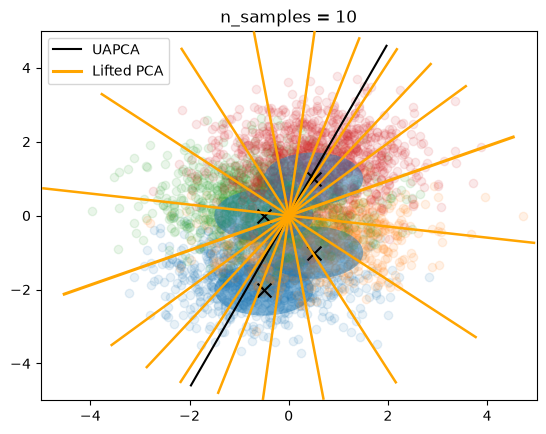

n=10 Lifted 0.09623363731635287 Distributional 1.1012437431630735


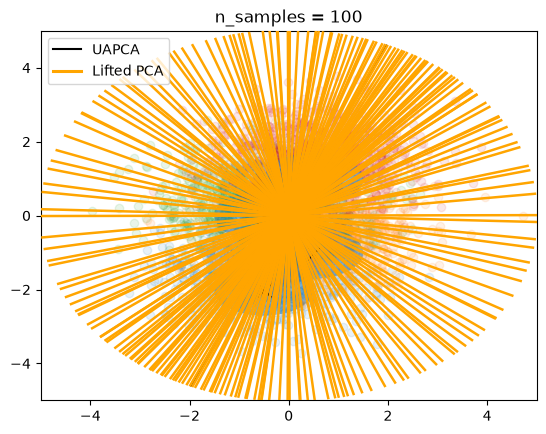

n=100 Lifted 0.06841139258513176 Distributional 1.1012437431630735


In [4]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10, 100]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

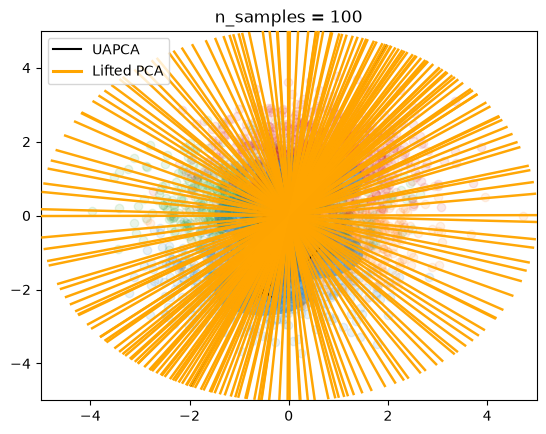

Barycenter cost: tensor(0.0693)


In [5]:
# Fix the support and optim over weights only (with good initialization)
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, eigenvectors_lifted, solver="fixed_support", seed=42, n_iter_bary=1000, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print("Barycenter cost:", lifted_pca.cost_barycenter(samples))

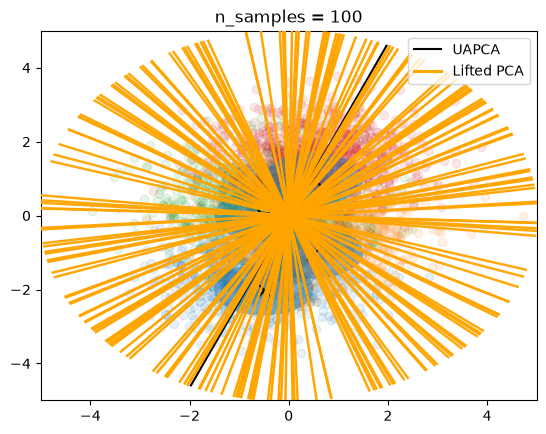

Barycenter cost: tensor(0.0896)


In [6]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=1000, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print("Barycenter cost:", lifted_pca.cost_barycenter(samples))

In [7]:
lifted_pca.weights_

tensor([0.0101, 0.0098, 0.0102, 0.0101, 0.0102, 0.0100, 0.0101, 0.0098, 0.0102,
        0.0100, 0.0101, 0.0101, 0.0102, 0.0099, 0.0102, 0.0101, 0.0101, 0.0099,
        0.0098, 0.0099, 0.0099, 0.0102, 0.0101, 0.0102, 0.0101, 0.0099, 0.0097,
        0.0101, 0.0101, 0.0098, 0.0101, 0.0100, 0.0100, 0.0100, 0.0099, 0.0098,
        0.0100, 0.0098, 0.0101, 0.0102, 0.0101, 0.0098, 0.0099, 0.0098, 0.0102,
        0.0101, 0.0098, 0.0101, 0.0102, 0.0102, 0.0101, 0.0097, 0.0100, 0.0101,
        0.0102, 0.0102, 0.0098, 0.0102, 0.0098, 0.0097, 0.0099, 0.0102, 0.0099,
        0.0097, 0.0098, 0.0098, 0.0098, 0.0100, 0.0099, 0.0098, 0.0099, 0.0102,
        0.0101, 0.0099, 0.0097, 0.0102, 0.0098, 0.0102, 0.0102, 0.0099, 0.0100,
        0.0098, 0.0102, 0.0100, 0.0101, 0.0099, 0.0100, 0.0101, 0.0102, 0.0100,
        0.0102, 0.0102, 0.0099, 0.0102, 0.0098, 0.0098, 0.0100, 0.0098, 0.0101,
        0.0102])

In [8]:
print(lifted_pca.weights_.max().item(), lifted_pca.weights_.min().item())

0.010201243403249188 0.009737606475818955


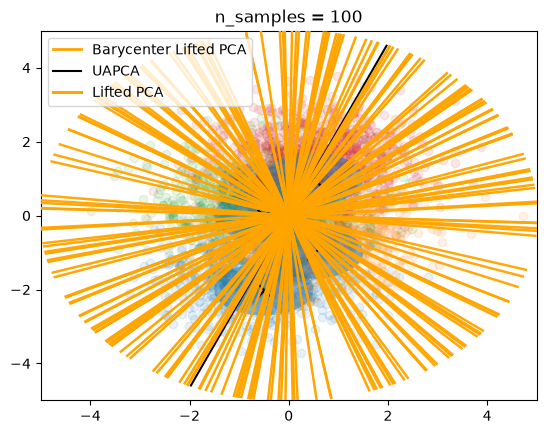

Barycenter cost: tensor(0.0896)


In [9]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

bary_lifted_pca = lifted_pca.get_barycenter_components().T

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy(), bary_lifted_pca=bary_lifted_pca)

print("Barycenter cost:", lifted_pca.cost_barycenter(samples))

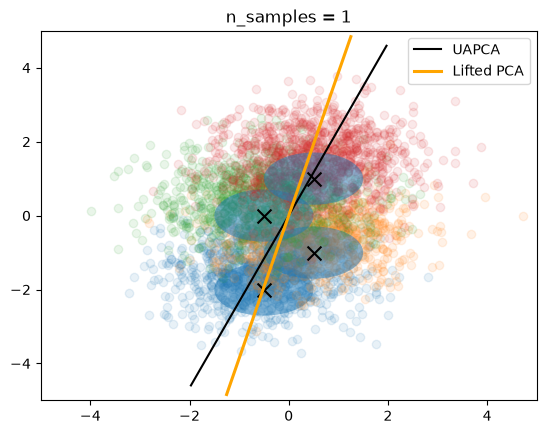

n=1 Lifted tensor(1.1209) Distributional 1.1012437431630735
[1.]


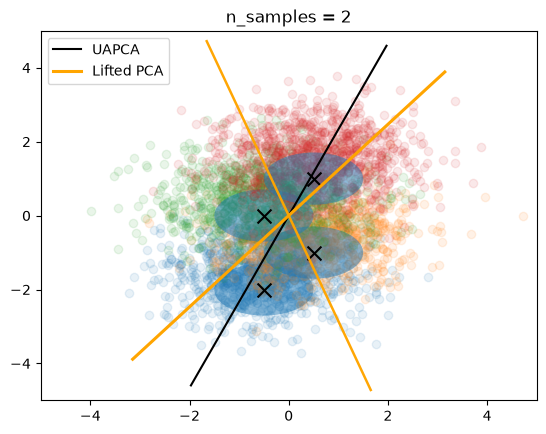

n=2 Lifted tensor(0.5472) Distributional 1.1012437431630735
[0.50505175 0.49494825]


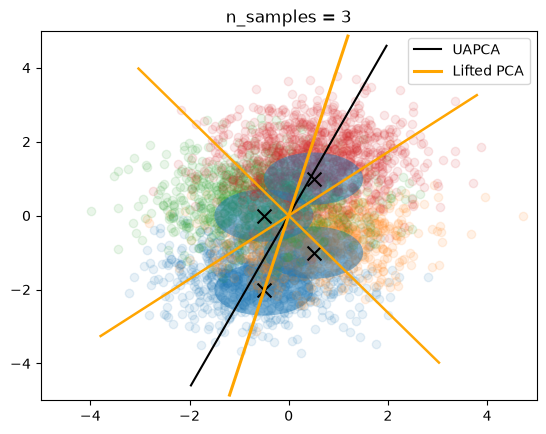

n=3 Lifted tensor(0.3232) Distributional 1.1012437431630735
[0.3266665  0.33560454 0.33772896]


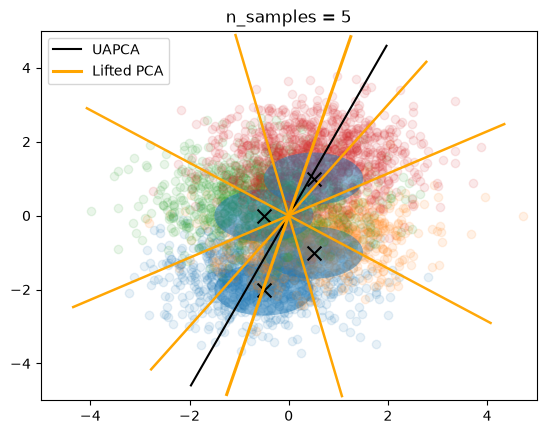

n=5 Lifted tensor(0.1752) Distributional 1.1012437431630735
[0.19424988 0.20289058 0.19993186 0.20004053 0.20288716]


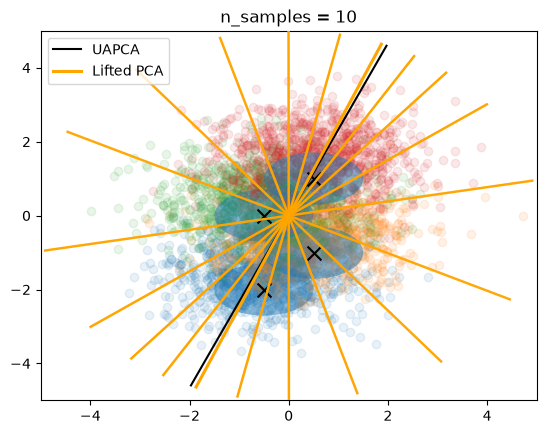

n=10 Lifted tensor(0.0976) Distributional 1.1012437431630735
[0.10119059 0.10131064 0.10144055 0.10079947 0.09845224 0.09810761
 0.09974247 0.10148787 0.0970043  0.10046426]


In [10]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())

## 1 Clear PC

In [11]:
n_distr = 100

x0 = torch.zeros((n_distr, 1))
x1 = torch.randn((n_distr, 1))
means = torch.concatenate([x0, x1], axis=1)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

# means = torch.randn((4, 2))

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

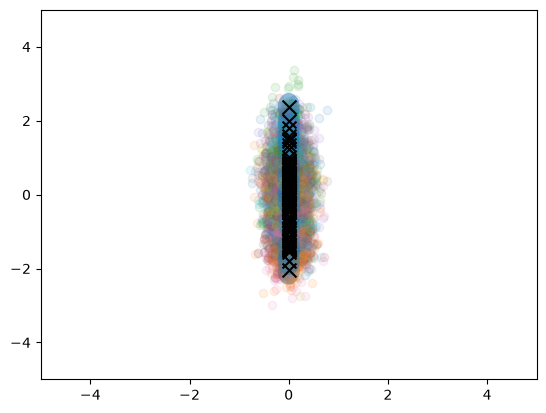

In [12]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

# for k in range(len(X_bar2)):
#     pc = ts[:,None] * X_bar2[k,:,0][None]
#     plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

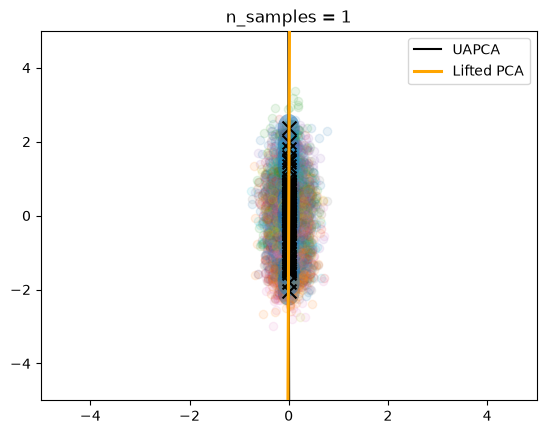

n=1 Lifted 0.050198027796740555 Distributional 0.0501774555102034


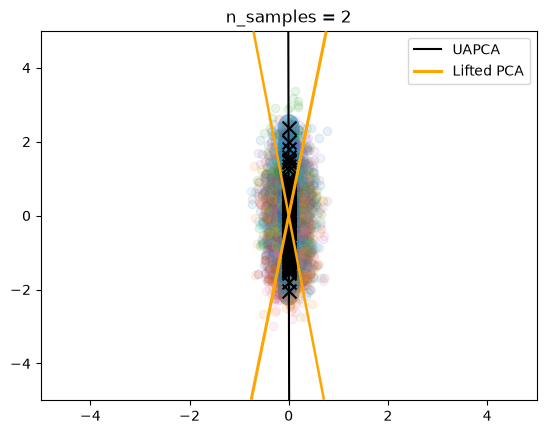

n=2 Lifted 0.029326206416697084 Distributional 0.0501774555102034


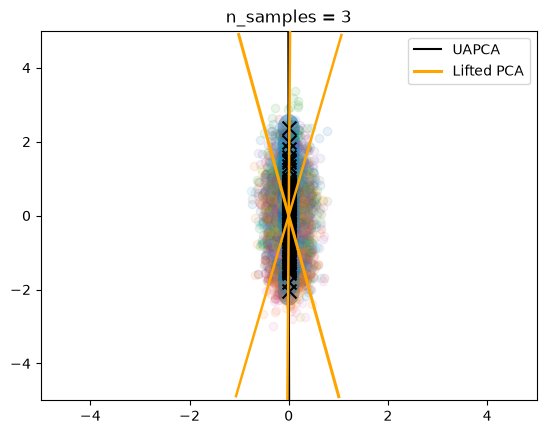

n=3 Lifted 0.023165064189448685 Distributional 0.0501774555102034


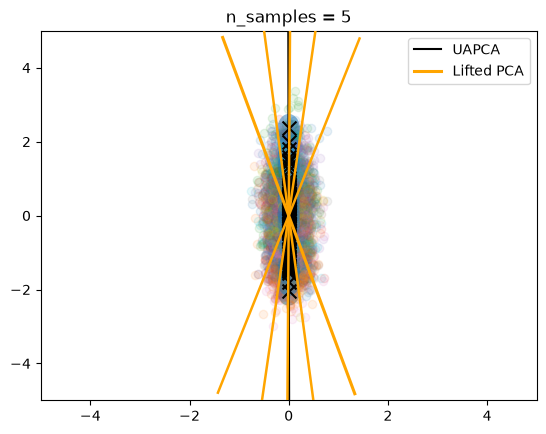

n=5 Lifted 0.018613783844565513 Distributional 0.0501774555102034


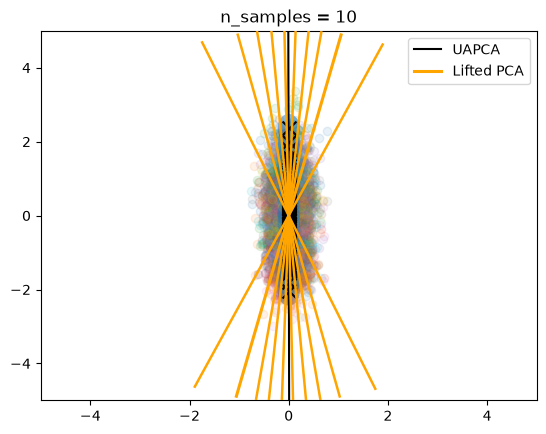

n=10 Lifted 0.015647932092323156 Distributional 0.0501774555102034


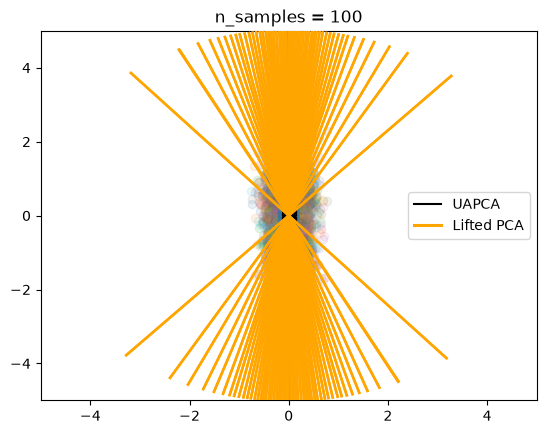

n=100 Lifted 0.013397926818985132 Distributional 0.0501774555102034


In [13]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10, 100]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples),
         means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

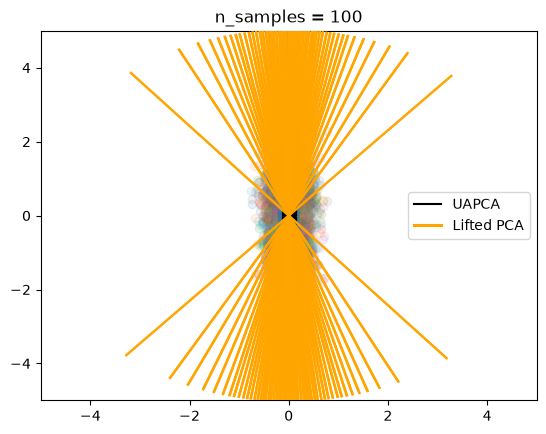

tensor(0.0136)


In [14]:
# Fix the support and optim over weights only (with good initialization)
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, eigenvectors_lifted, solver="fixed_support", n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

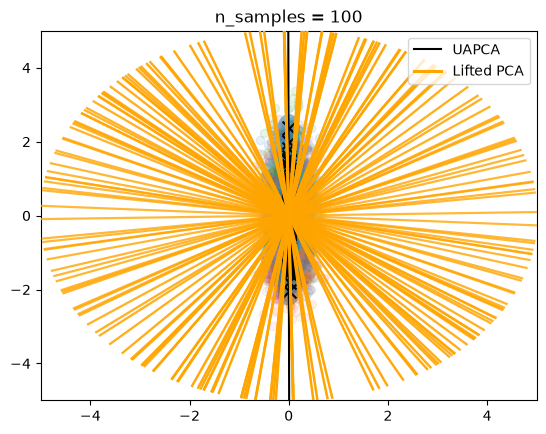

tensor(0.1680)


In [15]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", lr_bary=10, n_iter_bary=2000, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

In [16]:
lifted_pca.weights_

tensor([0.0085, 0.0115, 0.0089, 0.0088, 0.0094, 0.0105, 0.0090, 0.0085, 0.0114,
        0.0111, 0.0114, 0.0085, 0.0104, 0.0114, 0.0104, 0.0107, 0.0085, 0.0086,
        0.0088, 0.0095, 0.0106, 0.0103, 0.0097, 0.0089, 0.0089, 0.0106, 0.0098,
        0.0115, 0.0112, 0.0097, 0.0093, 0.0115, 0.0115, 0.0103, 0.0086, 0.0108,
        0.0084, 0.0091, 0.0093, 0.0087, 0.0086, 0.0093, 0.0115, 0.0100, 0.0108,
        0.0115, 0.0089, 0.0105, 0.0097, 0.0085, 0.0102, 0.0115, 0.0100, 0.0105,
        0.0099, 0.0114, 0.0091, 0.0108, 0.0092, 0.0115, 0.0095, 0.0101, 0.0111,
        0.0091, 0.0101, 0.0110, 0.0096, 0.0114, 0.0085, 0.0084, 0.0091, 0.0089,
        0.0085, 0.0103, 0.0115, 0.0085, 0.0094, 0.0103, 0.0110, 0.0092, 0.0096,
        0.0112, 0.0091, 0.0112, 0.0087, 0.0096, 0.0111, 0.0100, 0.0108, 0.0102,
        0.0111, 0.0111, 0.0115, 0.0115, 0.0111, 0.0098, 0.0087, 0.0102, 0.0115,
        0.0085])

In [17]:
print(lifted_pca.weights_.max(), lifted_pca.weights_.min())

tensor(0.0115) tensor(0.0084)


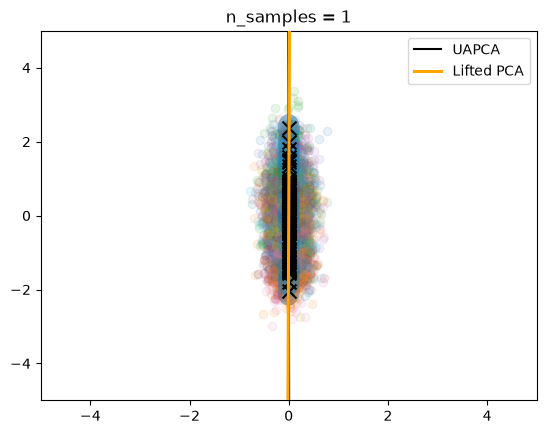

n=1 Lifted tensor(0.0502) Distributional 0.0501774555102034
[1.]


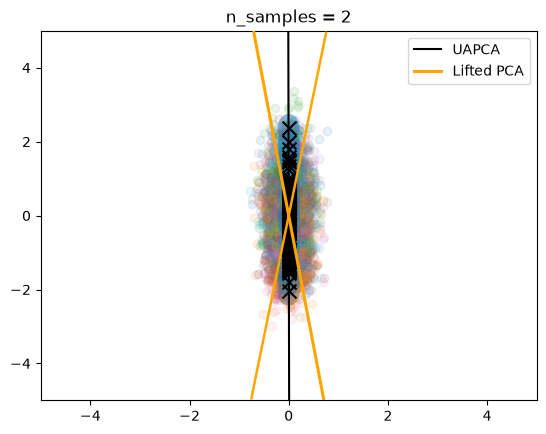

n=2 Lifted tensor(0.0293) Distributional 0.0501774555102034
[0.5017916 0.4982084]


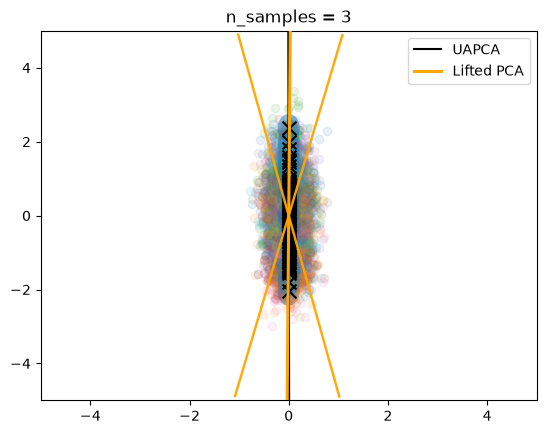

n=3 Lifted tensor(0.0231) Distributional 0.0501774555102034
[0.34701819 0.32813447 0.32484734]


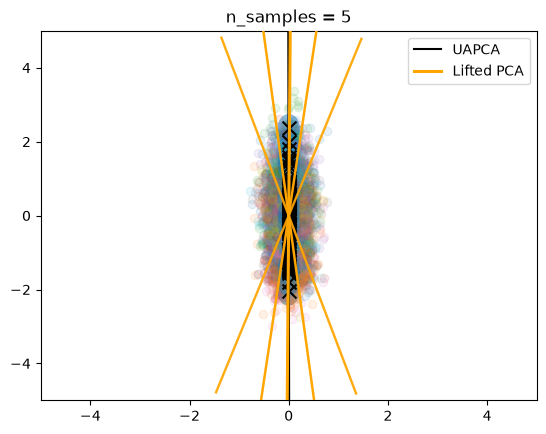

n=5 Lifted tensor(0.0185) Distributional 0.0501774555102034
[0.20855284 0.19149189 0.20544699 0.20619895 0.18830932]


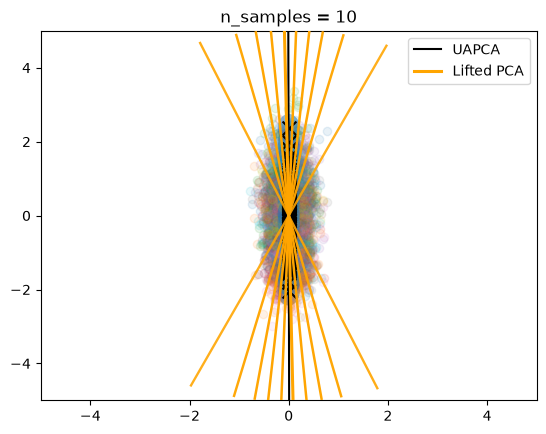

n=10 Lifted tensor(0.0155) Distributional 0.0501774555102034
[0.09977271 0.10233136 0.09925056 0.10208408 0.08974413 0.09227183
 0.10385742 0.10349579 0.10325344 0.10393869]


In [18]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())

## 2 Clear PC

In [19]:
n_distr = 100

x0 = torch.zeros((n_distr//2, 1))
x1 = torch.randn((n_distr//2, 1))
means0 = torch.concatenate([x0, x1], axis=1)
means1 = torch.concatenate([x1, x0], axis=1)
means = torch.concatenate([means0, means1], axis=0)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma0 = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigma1 = torch.diag(torch.tensor([1.5, 0.5])) * 0.1
Sigmas = torch.stack([Sigma0 if i<50 else Sigma1 for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

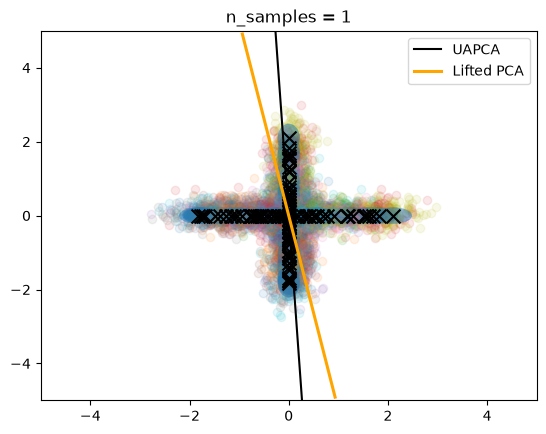

n=1 Lifted tensor(0.6212) Distributional 0.6208772844209259


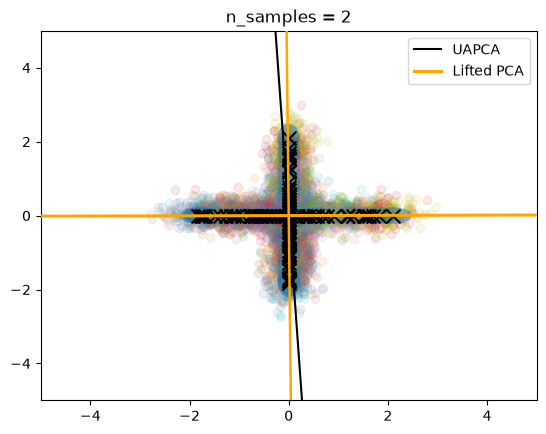

n=2 Lifted tensor(0.3631) Distributional 0.6208772844209259


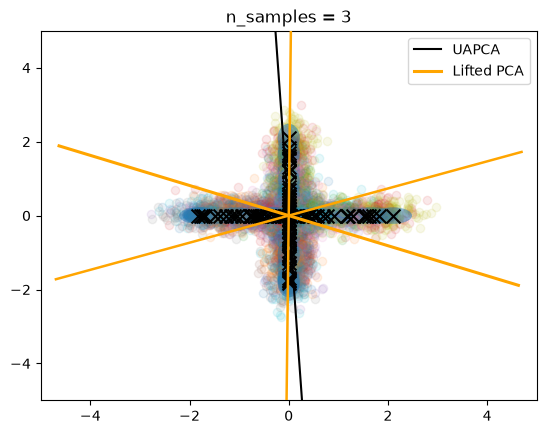

n=3 Lifted tensor(0.3483) Distributional 0.6208772844209259


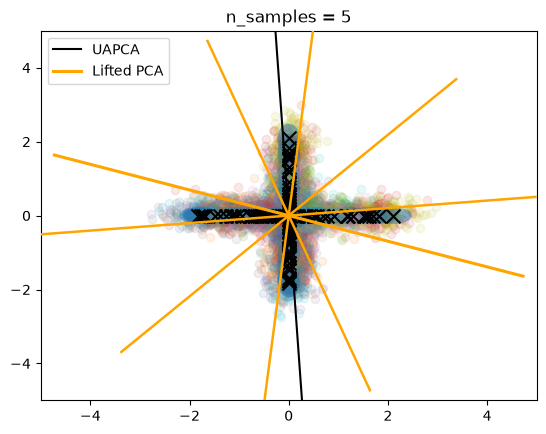

n=5 Lifted tensor(0.3123) Distributional 0.6208772844209259


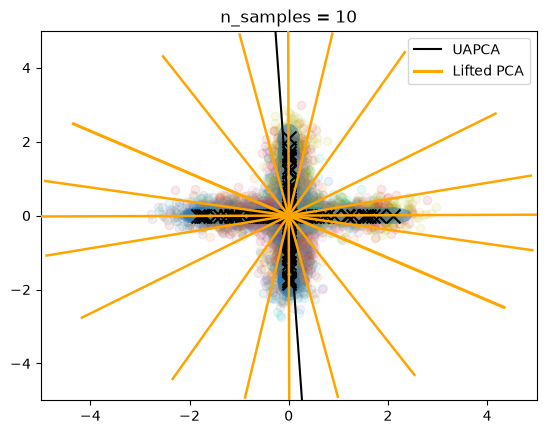

n=10 Lifted tensor(0.2973) Distributional 0.6208772844209259


In [20]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

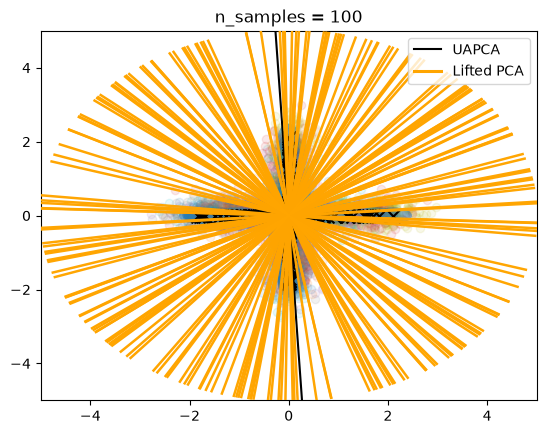

tensor(0.3024)


In [21]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

In [22]:
lifted_pca.weights_

tensor([0.0100, 0.0101, 0.0101, 0.0101, 0.0100, 0.0100, 0.0100, 0.0101, 0.0100,
        0.0100, 0.0099, 0.0100, 0.0100, 0.0101, 0.0100, 0.0101, 0.0101, 0.0099,
        0.0099, 0.0101, 0.0100, 0.0100, 0.0101, 0.0101, 0.0100, 0.0099, 0.0100,
        0.0099, 0.0100, 0.0101, 0.0099, 0.0100, 0.0100, 0.0100, 0.0099, 0.0101,
        0.0100, 0.0099, 0.0100, 0.0100, 0.0100, 0.0099, 0.0101, 0.0100, 0.0100,
        0.0101, 0.0099, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0099,
        0.0100, 0.0101, 0.0100, 0.0099, 0.0099, 0.0100, 0.0101, 0.0100, 0.0099,
        0.0100, 0.0099, 0.0101, 0.0100, 0.0100, 0.0100, 0.0101, 0.0101, 0.0100,
        0.0099, 0.0099, 0.0100, 0.0100, 0.0101, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0101, 0.0100, 0.0100, 0.0099, 0.0099, 0.0100, 0.0100, 0.0100, 0.0100,
        0.0100, 0.0100, 0.0100, 0.0099, 0.0101, 0.0101, 0.0100, 0.0099, 0.0100,
        0.0100])

In [23]:
lifted_pca.weights_.max()

tensor(0.0101)

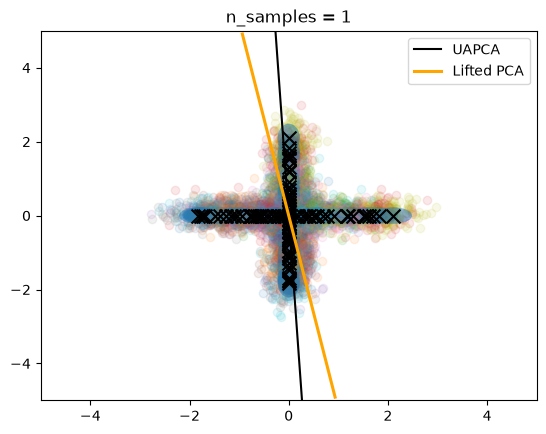

n=1 Lifted tensor(0.6212) Distributional 0.6208772844209259
[1.]


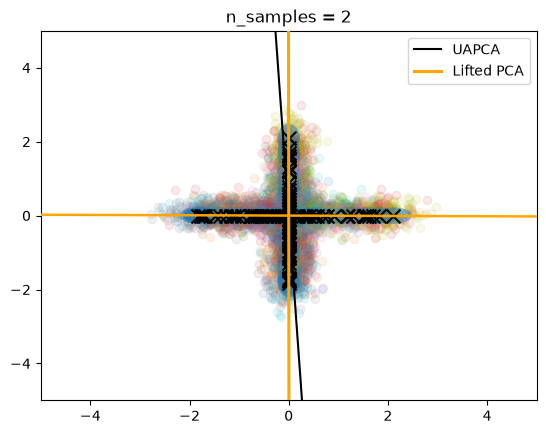

n=2 Lifted tensor(0.3631) Distributional 0.6208772844209259
[0.49836776 0.50163224]


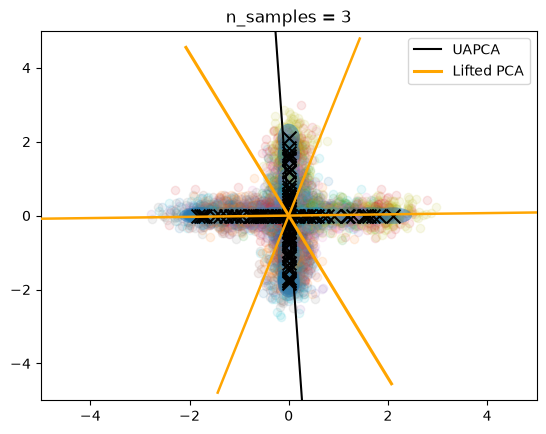

n=3 Lifted tensor(0.3443) Distributional 0.6208772844209259
[0.33480954 0.3316338  0.33355666]


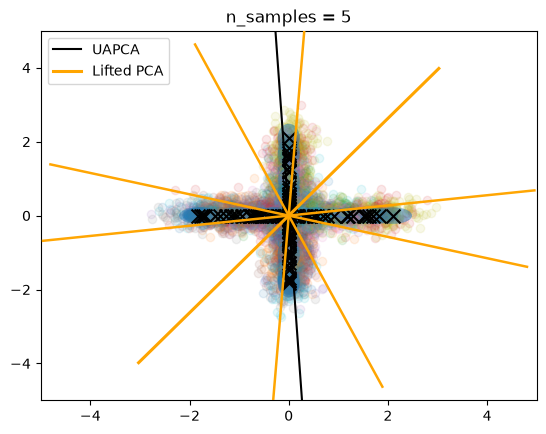

n=5 Lifted tensor(0.3122) Distributional 0.6208772844209259
[0.19927913 0.19956292 0.19855992 0.20081117 0.20178686]


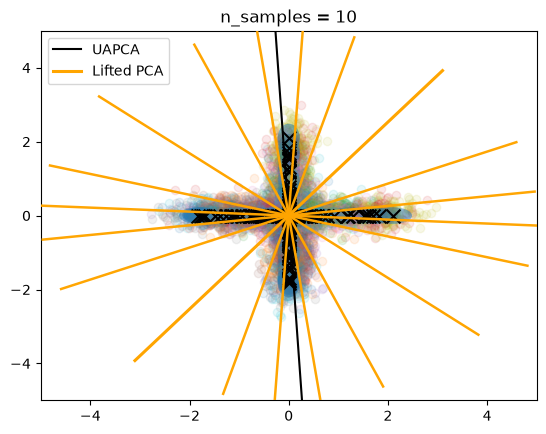

n=10 Lifted tensor(0.2976) Distributional 0.6208772844209259
[0.09927    0.10011164 0.10001413 0.09980305 0.09960691 0.10041021
 0.09986931 0.10089993 0.10082606 0.09918876]


In [24]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())